# 6. Hafta | Kendi Projemin Veri Analizi — Ekip Teslim Şablonu

**Grup:** [Sude Nur Özkan, Berra Suer, Gizem Görgün] • **Proje:** [Hayvan Barınaklarındaki Sahiplenme Oranlarının Analizi] • **Ekip görevleri:** [Sude Nur Özkan - Data Analyst & Developer, Berra Suer - Developer & Tester, Gizem Görgün - Tester & Documentation Officer]

Bu notebook başlangıç iskeletidir. Örnek dosya ve kodu kendi araştırma/proje verinize uyarlayın. **Veri uydurup gerçek ölçüm gibi sunmayın.**

## A. Veri tanıtımı
- Veri setinin adı ve bağlantısı: Austin Animal Center Intakes (10/01/2013 to 05/05/2025), Austin Animal Center Outcomes (10/01/2013 to 05/05/2025)
https://www.kaggle.com/datasets/jackdaoud/animal-shelter-analytics/data
- Veri kaynağı / lisans / erişim tarihi: Veri Setlerinin Kaynakları:
Austin Animal Center Intakes (10/01/2013 to 05/05/2025), Austin Animal Center Outcomes (10/01/2013 to 05/05/2025) Lisans:Public Domain
- CSV mi, JSON mu?: CVS
- Satır ve sütunların anlamı: -Satır ve sütunların anlamı: Her satır bir hayvana ait kayıtları temsil etmektedir. Sütunlar ise hayvanın kimlik numarası (Animal ID), türü, yaşı, ırkı, rengi, cinsiyeti, barınağa kabul tarihi ve kabul türü gibi bilgileri içermektedir. Sonuç veri setinde ise hayvanın sahiplenilme durumu ve çıkış bilgileri yer almaktadır.
- Ölçü birimi ve gözlem sayısı: - Ölçü birimi ve gözlem sayısı: Veri setinde yaş bilgileri yıl, ay ve gün cinsinden; tarihler tarih formatında tutulmaktadır. Yeni Austin Animal Center Intakes veri seti yaklaşık 19.000 gözlem ve 15 sütundan oluşmaktadır.
- Gerçek mi / açık kaynak mı / temsili mi?: Gerçek verilerden oluşan, Austin Animal Center tarafından yayımlanan açık veri setidir.
- Ekip üyelerinin görevleri: Sude Nur Özkan - Data Analyst & Developer
Berra Suer - Developer & Tester
Gizem Görgün - Tester & Documentation Officer

https://github.com/ozkansude06/Animal-Shelter-Project.git

## B. Başlangıç: temsili veriyle çalışan örnek
Aşağıdaki örneği çalıştırın. Ardından **kendi dosyanızı** `veri_yolu` değişkeniyle gösterebilirsiniz.

In [ ]:
from pathlib import Path
import pandas as pd

ornek = pd.DataFrame({"isim": ["Max", "Luna", "Artemis", "Diana", "Usagi"],
                      "cins": ["köpek", "kedi", "kedi", "kedi", "kedi"],
                      "cinsiyet": ["kız", "kız", "erkek", "kız", "erkek"]})
ornek.to_csv("Austin_Animal_Center_Intakes_(10_01_2013_to_05_05_2025)_20261118.csv", index=False)
veri_yolu = "Austin_Animal_Center_Intakes_(10_01_2013_to_05_05_2025)_20261118.csv"  # Kendi dosyanıza göre değiştirin
veri = pd.read_csv(veri_yolu)
print(veri.head())

      isim   cins cinsiyet
0      Max  köpek      kız
1     Luna   kedi      kız
2  Artemis   kedi    erkek
3    Diana   kedi      kız
4    Usagi   kedi    erkek


## C. Veri inceleme ve hesaplama
Kendi veri setinizi kullanırken sayısal sütun adlarını değiştirin. Sütun başlığında boşluk ve yazım farklarını kontrol edin.

In [ ]:
import pandas as pd

intakes = pd.read_csv("Austin_Animal_Center_Intakes_(10_01_2013_to_05_05_2025)_20261118.csv")
outcomes = pd.read_csv("Austin_Animal_Center_Outcomes_(10_01_2013_to_05_05_2025)_20261118.csv")


# Hayvan giriş verilerini inceleme
print("GİRİŞ VERİLERİ")
print("Boyut:", intakes.shape)
print("Eksik değerler:")
print(intakes.isna().sum())

print("\nÇIKIŞ VERİLERİ")
print("Boyut:", outcomes.shape)
print("Eksik değerler:")
print(outcomes.isna().sum())

GİRİŞ VERİLERİ
Boyut: (5, 3)
Eksik değerler:
isim        0
cins        0
cinsiyet    0
dtype: int64

ÇIKIŞ VERİLERİ
Boyut: (173775, 12)
Eksik değerler:
Animal ID               0
Date of Birth           0
Name                49784
DateTime                0
MonthYear               0
Outcome Type           46
Outcome Subtype     94115
Animal Type             0
Sex upon Outcome        1
Age upon Outcome        9
Breed                   0
Color                   0
dtype: int64


## D. Grafik ve sonuç dosyaları
Grafiğin başlığını, eksenini ve ölçü birimini kendi verinize göre güncelleyin.

KeyError: 'Animal Type'

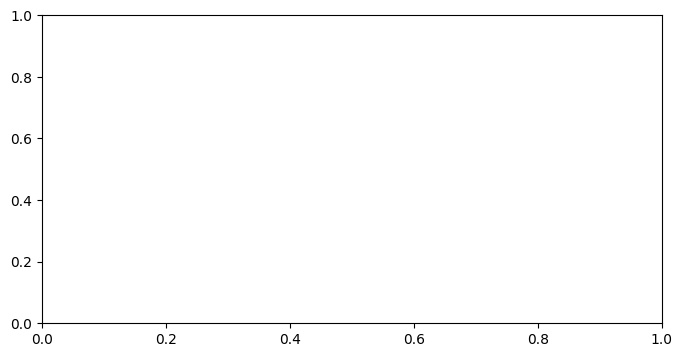

In [ ]:
import matplotlib.pyplot as plt
from pathlib import Path

klasor = Path("sonuc")
klasor.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(8, 4))

tur_sayilari = intakes["Animal Type"].value_counts()

ax.bar(tur_sayilari.index, tur_sayilari.values, color="teal")
ax.set_xlabel("Hayvan Türü")
ax.set_ylabel("Hayvan Sayısı")
ax.set_title("Hayvan Türlerine Göre Giriş Dağılımı")

fig.tight_layout()
fig.savefig(klasor / "grafik.png", dpi=160)

intakes.to_csv(klasor / "kullanilan_veri.csv", index=False)

plt.show()

## E. Akademik yorum
**Veri kaynağı ve değişken:** ustin Animal Center tarafından yayımlanan açık veri setinin hayvan giriş kayıtları kullanılmıştır. Analizde hayvan türü değişkeni incelenmiş ve hayvanların türlerine göre dağılımı değerlendirilmiştir.

**Toplam / ortalama ve birimler:** Hayvan giriş kayıtlarının toplam sayısı incelenmiştir. Hayvan türlerine göre kayıt sayıları hesaplanmıştır. Sayım sonuçlarının birimi hayvandır. Ortalama hesaplaması henüz yapılmamıştır.

**Grafikte görülen bulgu:** Grafikte hayvan girişlerinin türlere göre dağılımı gösterilmiştir. Hangi hayvan türünün barınağa daha fazla kabul edildiği ve türler arasındaki sayısal farklılıklar gözlemlenebilmektedir.

**Sınırlılıklar ve ölçemediği şeyler:** Veri seti hayvanların giriş kayıtlarını göstermektedir. Tek başına bir hayvanın gelecekte sahiplendirilip sahiplendirilmeyeceğini açıklamaz. Ayrıca tür dağılımı, sahiplendirilme başarısını doğrudan göstermez.

**Ekipçe yapılan işlem:** Hayvan giriş ve çıkış veri setleri ayrı ayrı okunmuş, giriş verilerinin boyutu ve eksik değerleri incelenmiştir. Hayvan türlerine göre dağılım grafiği oluşturulmuş ve sonuç dosyaları kaydedilmiştir.

> Grafikte iki değişken birlikte görünse bile tek başına neden-sonuç kanıtı oluşmaz.

## F. Teslim kontrolü
- [ ] Çalışır `.ipynb` dosyası
- [ ] CSV/JSON örneği veya yasal ve erişilebilir veri kaynağı
- [ ] Birim + veri kaynağı + lisans
- [ ] En az 1 açıklamalı grafik
- [ ] Toplam ve ortalama hesabı
- [ ] 4–5 cümlelik yorum
- [ ] README içinde ekip katkıları
- [ ] GitHub repo bağlantısı
- [ ] Gizli/kişisel veri ve anahtar bulunmuyor